Задание для самостоятельной работы (ДЗ 6)
Запустите DBSCAN на датасете Wine (с параметрами eps=1.5, min_samples=5).
Посчитайте silhouette_score и adjusted_rand_score.
Сравните с KMeans. Какой алгоритм лучше справился с поиском истинных сортов? Почему?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs, make_moons, make_circles, load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score, davies_bouldin_score

# Алгоритмы
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering, SpectralClustering
from sklearn.mixture import GaussianMixture

# Для дендрограммы
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

# Настройки графиков
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('viridis')
np.random.seed(42)

Silhouette Score: 0.285
Adjusted Rand Index (сравнение с истиной): 0.897


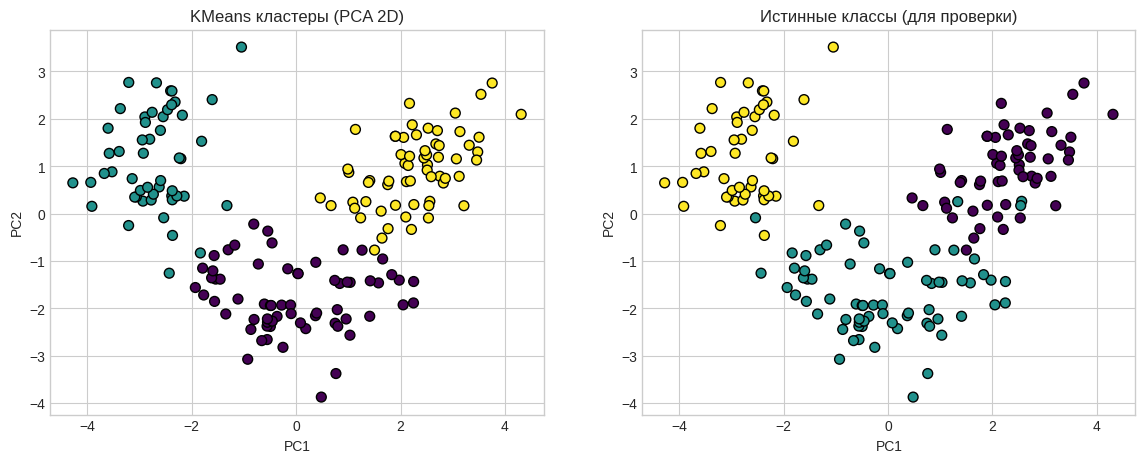

In [5]:
wine = load_wine()
X_wine = wine.data
y_true_wine = wine.target

# Обязательное масштабирование
X_wine_scaled = StandardScaler().fit_transform(X_wine)

# Понижаем размерность до 2D для визуализации
pca = PCA(n_components=2, random_state=42)
X_wine_pca = pca.fit_transform(X_wine_scaled)

# Кластеризация KMeans
km_wine = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_wine = km_wine.fit_predict(X_wine_scaled)

print(f"Silhouette Score: {silhouette_score(X_wine_scaled, labels_wine):.3f}")
print(f"Adjusted Rand Index (сравнение с истиной): {adjusted_rand_score(y_true_wine, labels_wine):.3f}")

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.scatter(X_wine_pca[:, 0], X_wine_pca[:, 1], c=labels_wine, cmap='viridis', s=50, edgecolor='k')
plt.title('KMeans кластеры (PCA 2D)')
plt.xlabel('PC1')
plt.ylabel('PC2')

plt.subplot(1, 2, 2)
plt.scatter(X_wine_pca[:, 0], X_wine_pca[:, 1], c=y_true_wine, cmap='viridis', s=50, edgecolor='k')
plt.title('Истинные классы (для проверки)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

In [6]:
# Кластеризация DBSCAN
for i in [0.001, 0.01, 0.1, 1, 1.5]:
  for j in range(2, 20):
    dbscan_wine = DBSCAN(eps=i, min_samples=j)
    labels_wine = dbscan_wine.fit_predict(X_wine_scaled)
    try:
      print(f"Silhouette Score для {i} и {j}: {silhouette_score(X_wine_scaled, labels_wine):.3f}")
    except:
      print(f"мимо {i} и {j}")

мимо 0.001 и 2
мимо 0.001 и 3
мимо 0.001 и 4
мимо 0.001 и 5
мимо 0.001 и 6
мимо 0.001 и 7
мимо 0.001 и 8
мимо 0.001 и 9
мимо 0.001 и 10
мимо 0.001 и 11
мимо 0.001 и 12
мимо 0.001 и 13
мимо 0.001 и 14
мимо 0.001 и 15
мимо 0.001 и 16
мимо 0.001 и 17
мимо 0.001 и 18
мимо 0.001 и 19
мимо 0.01 и 2
мимо 0.01 и 3
мимо 0.01 и 4
мимо 0.01 и 5
мимо 0.01 и 6
мимо 0.01 и 7
мимо 0.01 и 8
мимо 0.01 и 9
мимо 0.01 и 10
мимо 0.01 и 11
мимо 0.01 и 12
мимо 0.01 и 13
мимо 0.01 и 14
мимо 0.01 и 15
мимо 0.01 и 16
мимо 0.01 и 17
мимо 0.01 и 18
мимо 0.01 и 19
мимо 0.1 и 2
мимо 0.1 и 3
мимо 0.1 и 4
мимо 0.1 и 5
мимо 0.1 и 6
мимо 0.1 и 7
мимо 0.1 и 8
мимо 0.1 и 9
мимо 0.1 и 10
мимо 0.1 и 11
мимо 0.1 и 12
мимо 0.1 и 13
мимо 0.1 и 14
мимо 0.1 и 15
мимо 0.1 и 16
мимо 0.1 и 17
мимо 0.1 и 18
мимо 0.1 и 19
мимо 1 и 2
мимо 1 и 3
мимо 1 и 4
мимо 1 и 5
мимо 1 и 6
мимо 1 и 7
мимо 1 и 8
мимо 1 и 9
мимо 1 и 10
мимо 1 и 11
мимо 1 и 12
мимо 1 и 13
мимо 1 и 14
мимо 1 и 15
мимо 1 и 16
мимо 1 и 17
мимо 1 и 18
мимо 1 и 19
Silhou

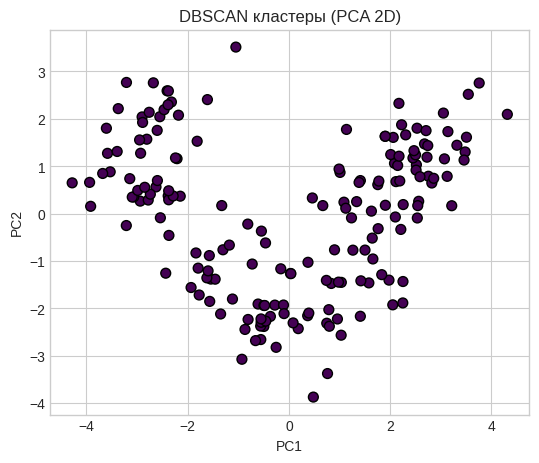

In [7]:
plt.figure(figsize=(21, 5))
plt.subplot(1, 3, 1)
plt.scatter(X_wine_pca[:, 0], X_wine_pca[:, 1], c=labels_wine, cmap='viridis', s=50, edgecolor='k')
plt.title('DBSCAN кластеры (PCA 2D)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()